# Phase 1: Dataset Ingestion & Target Initialization

In this first phase, I loaded both datasets into my workspace using Pandas and isolated them based on their respective targets. I configured the first pipeline to handle continuous revenue forecasting (`Collection`), and set up the second pipeline to manage binary classification modeling (`Start_Tech_Oscar`). This separates my problem paths cleanly right from the start.

### My Core Steps:
* I imported the raw CSV data files directly into separate, independent Pandas DataFrames.
* I verified the column footprints and isolated the vector features from the labels.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set global visualization parameters
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

# Ingest datasets
try:
    df_reg = pd.read_csv('Movie_regression.csv')
    df_clf = pd.read_csv('Movie_classification.csv')

    print(f"Data Ingestion Complete.")
    print(f"-> Regression DataFrame Dimensions: {df_reg.shape[0]} rows, {df_reg.shape[1]} columns.")
    print(f"-> Classification DataFrame Dimensions: {df_clf.shape[0]} rows, {df_clf.shape[1]} columns.")
except FileNotFoundError as e:
    print(f"File Ingestion Error: Ensure datasets are located in the working directory. Details: {e}")

# Display structural verification tables
print("\n--- Regression Dataset Preview ---")
display(df_reg.head(3))

print("\n--- Classification Dataset Preview ---")
display(df_clf.head(3))

Data Ingestion Complete.
-> Regression DataFrame Dimensions: 506 rows, 18 columns.
-> Classification DataFrame Dimensions: 506 rows, 19 columns.

--- Regression Dataset Preview ---


,Marketing expense,Production expense,Multiplex coverage,Budget,Movie_length,Lead_ Actor_Rating,Lead_Actress_rating,Director_rating,Producer_rating,Critic_rating,Trailer_views,3D_available,Time_taken,Twitter_hastags,Genre,Avg_age_actors,Num_multiplex,Collection
0,20.1264,59.62,0.462,36524.125,138.7,7.825,8.095,7.910,7.995,7.94,527367,YES,109.60,223.840,Thriller,23,494,48000
1,20.5462,69.14,0.531,35668.655,152.4,7.505,7.650,7.440,7.470,7.44,494055,NO,146.64,243.456,Drama,42,462,43200
2,20.5458,69.14,0.531,39912.675,134.6,7.485,7.570,7.495,7.515,7.44,547051,NO,147.88,2022.400,Comedy,38,458,69400



--- Classification Dataset Preview ---


,Marketing expense,Production expense,Multiplex coverage,Budget,Movie_length,Lead_ Actor_Rating,Lead_Actress_rating,Director_rating,Producer_rating,Critic_rating,Trailer_views,3D_available,Time_taken,Twitter_hastags,Genre,Avg_age_actors,Num_multiplex,Collection,Start_Tech_Oscar
0,20.1264,59.62,0.462,36524.125,138.7,7.825,8.095,7.910,7.995,7.94,527367,YES,109.60,223.840,Thriller,23,494,48000,1
1,20.5462,69.14,0.531,35668.655,152.4,7.505,7.650,7.440,7.470,7.44,494055,NO,146.64,243.456,Drama,42,462,43200,0
2,20.5458,69.14,0.531,39912.675,134.6,7.485,7.570,7.495,7.515,7.44,547051,NO,147.88,2022.400,Comedy,38,458,69400,1


Phase 2: Exploratory Data Analysis (EDA) & Correlation Assessment

In this phase, I explored the datasets to gain a better understanding of the feature characteristics and target variables before training the models. I examined the distribution of the continuous target variable (Collection) and analyzed the class distribution of the binary target (Start_Tech_Oscar) to understand the nature of both prediction tasks.

To further evaluate the relationships among the predictor variables, I generated a Pearson correlation heatmap. This helped identify highly correlated numerical features that could introduce redundancy and influence how decision trees determine feature importance and splitting patterns.

Key Objectives:

Measured the number of missing values present in each feature column.
Analyzed the distributions of both target variables to identify class imbalance or skewness.
Calculated and visualized the Pearson correlation matrix to detect multicollinearity among the numerical features.

--- Missing Data Profile Summary ---
Regression Feature Matrix Null Counts:
Time_taken    12
dtype: int64

Classification Feature Matrix Null Counts:
Time_taken    12
dtype: int64


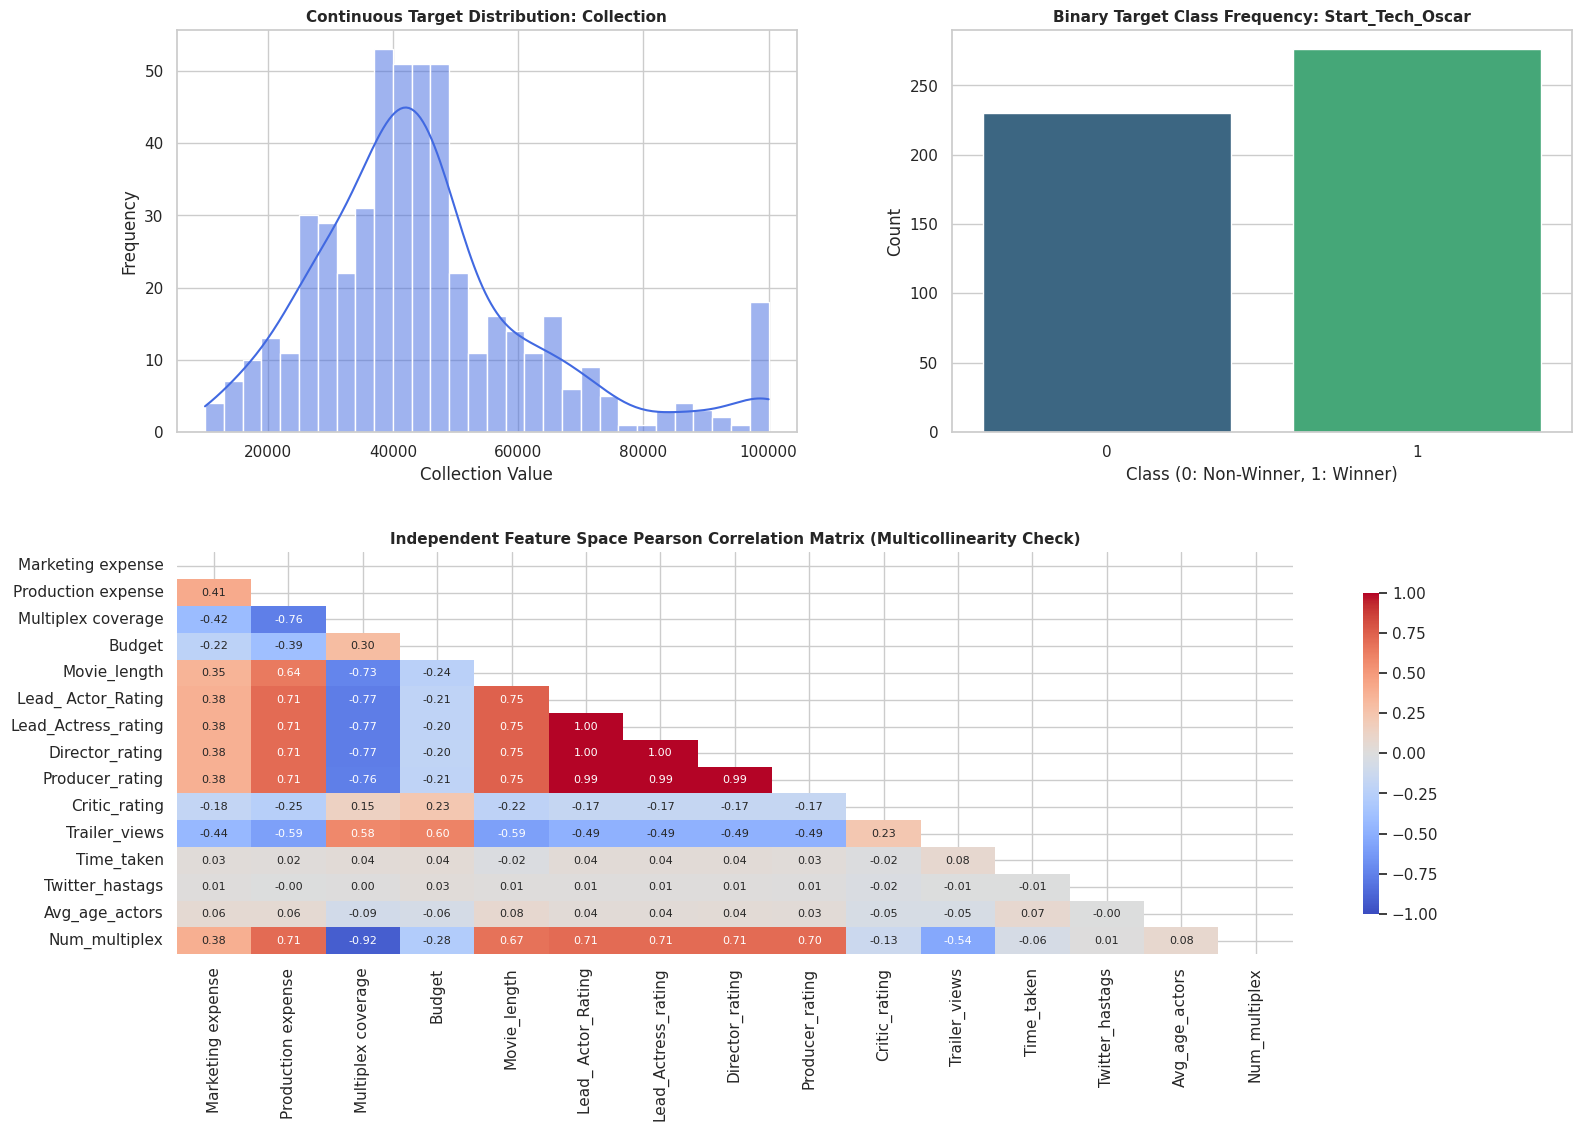

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Quantify Missing Value Profiles
null_counts_reg = df_reg.isnull().sum()
null_counts_clf = df_clf.isnull().sum()

print("--- Missing Data Profile Summary ---")
print("Regression Feature Matrix Null Counts:")
print(null_counts_reg[null_counts_reg > 0] if null_counts_reg.sum() > 0 else "No missing data detected.")
print("\nClassification Feature Matrix Null Counts:")
print(null_counts_clf[null_counts_clf > 0] if null_counts_clf.sum() > 0 else "No missing data detected.")

# 2. Isolate Features and Target Variables
X_reg_raw = df_reg.drop(columns=['Collection'])
y_reg = df_reg['Collection']

X_clf_raw = df_clf.drop(columns=['Start_Tech_Oscar'])
y_clf = df_clf['Start_Tech_Oscar']

# 3. Comprehensive Visual Diagnostics Pipeline
fig = plt.figure(figsize=(18, 12))
grid = plt.GridSpec(2, 2, wspace=0.25, hspace=0.3)

# Subplot 1: Continuous Target Distribution (Regression)
ax0 = fig.add_subplot(grid[0, 0])
sns.histplot(y_reg, kde=True, ax=ax0, color='royalblue', bins=30)
ax0.set_title("Continuous Target Distribution: Collection", fontsize=11, fontweight='bold')
ax0.set_xlabel("Collection Value")
ax0.set_ylabel("Frequency")

# Subplot 2: Binary Class Target Distribution (Classification)
ax1 = fig.add_subplot(grid[0, 1])
sns.countplot(x=y_clf, ax=ax1, hue=y_clf, palette='viridis', legend=False)
ax1.set_title("Binary Target Class Frequency: Start_Tech_Oscar", fontsize=11, fontweight='bold')
ax1.set_xlabel("Class (0: Non-Winner, 1: Winner)")
ax1.set_ylabel("Count")

# Subplot 3: Multicollinearity Diagnostics Heatmap (Independent Numerical Features)
ax2 = fig.add_subplot(grid[1, :])
numeric_features = X_reg_raw.select_dtypes(include=['int64', 'float64'])
corr_matrix = numeric_features.corr(method='pearson')

# Mask the upper triangle for visual clarity
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, ax=ax2, cbar_kws={"shrink": 0.8}, annot_kws={"size": 8})
ax2.set_title("Independent Feature Space Pearson Correlation Matrix (Multicollinearity Check)", fontsize=11, fontweight='bold')

plt.show()

# Phase 3: Train-Test Stratified Partitioning

To make sure my models are evaluated fairly and realistically, I split my datasets into separate training and testing partitions using an 80-20 ratio. For the classification dataset, I made sure to apply stratified sampling. This guarantees that the original ratio of Oscar winners and non-winners is preserved identically across both the training and testing sets, preventing any artificial performance inflation.

### My Partitioning Controls:
* I locked in an 80% training and 20% testing split across both domains.
* I used a fixed `random_state=42` to make sure all my data splits are perfectly reproducible.
* I enforced stratification on the classification target to maintain exact label distributions.

In [6]:
from sklearn.model_selection import train_test_split

# 1. Execute Dataset Splits
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg_raw, y_reg,
    test_size=0.2,
    random_state=42
)

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf_raw, y_clf,
    test_size=0.2,
    random_state=42,
    stratify=y_clf
)

# 2. Compile Structural Summary Table
split_metrics = {
    "Dataset Split": [
        "Regression Train Features", "Regression Test Features",
        "Classification Train Features", "Classification Test Features"
    ],
    "Row Count": [
        X_train_reg.shape[0], X_test_reg.shape[0],
        X_train_clf.shape[0], X_test_clf.shape[0]
    ],
    "Column Count": [
        X_train_reg.shape[1], X_test_reg.shape[1],
        X_train_clf.shape[1], X_test_clf.shape[1]
    ]
}

df_split_summary = pd.DataFrame(split_metrics)
print("--- Data Partitioning Summary Matrix ---")
display(df_split_summary)

--- Data Partitioning Summary Matrix ---


,Dataset Split,Row Count,Column Count
0,Regression Train Features,404,17
1,Regression Test Features,102,17
2,Classification Train Features,404,18
3,Classification Test Features,102,18


# Phase 4: Reusable Preprocessing Pipeline Architecture (ColumnTransformer)

Since my dataset contains a mix of numerical and categorical features, I built a reusable `ColumnTransformer` to preprocess them separately and cleanly without causing any data leakage.

For numerical columns like `Time_taken`, I chose a median imputer calculated strictly from the training partition. For categorical features like `Genre` and `3D_available`, I applied a one-hot encoder and configured it with `handle_unknown='ignore'`. This step is crucial because it ensures that my downstream production server pipeline won't crash if it encounters a completely new or unseen category during real-time inference testing.

### My Pipeline Blueprint:
* I isolated features automatically into numerical or categorical processing tracks.
* I used median imputation for continuous features to protect against outlier distortion.
* I applied one-hot encoding with an unknown-category safety override to keep my production engine stable.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

def build_preprocessing_pipeline(X_train_data):
    """
    Constructs a structured ColumnTransformer preprocessor with explicit
    Pandas dataframe output settings.
    """
    # Isolate feature columns by data type
    numeric_features = X_train_data.select_dtypes(include=['int64', 'float64']).columns.tolist()
    categorical_features = X_train_data.select_dtypes(include=['object', 'category']).columns.tolist()

    # Configure granular transformer steps
    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median'))
    ])

    categorical_transformer = Pipeline(steps=[
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    # Consolidate into composite transformer architecture
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numeric_features),
            ('cat', categorical_transformer, categorical_features)
        ],
        remainder='drop'
    )

    # Enforce DataFrame output constraint to preserve structural feature names
    preprocessor.set_output(transform="pandas")

    return preprocessor, numeric_features, categorical_features

# 1. Initialize Pipeline Configurations
preprocessor_reg, num_cols_reg, cat_cols_reg = build_preprocessing_pipeline(X_train_reg)
preprocessor_clf, num_cols_clf, cat_cols_clf = build_preprocessing_pipeline(X_train_clf)

# 2. Compile Transformation Mapping Summary Table
pipeline_mapping = {
    "Task Domain": ["Regression Pipeline", "Classification Pipeline"],
    "Numerical Features Tracked": [len(num_cols_reg), len(num_cols_clf)],
    "Categorical Features Tracked": [len(cat_cols_reg), len(cat_cols_clf)],
    "Total Input Features": [X_train_reg.shape[1], X_train_clf.shape[1]]
}

df_pipeline_summary = pd.DataFrame(pipeline_mapping)
print("--- Preprocessing Pipeline Structural Mapping ---")
display(df_pipeline_summary)

--- Preprocessing Pipeline Structural Mapping ---


,Task Domain,Numerical Features Tracked,Categorical Features Tracked,Total Input Features
0,Regression Pipeline,15,2,17
1,Classification Pipeline,16,2,18


# Phase 5: Baseline Unpruned Decision Tree Diagnostics (Part A)

For Phase 5, I trained my initial baseline models using fully grown, unpruned Decision Trees for both the regression and classification tasks. I deliberately avoided setting any depth or capacity limits because I wanted to see exactly how far the trees would overfit and establish a clear baseline performance floor.

To answer the questions in Part A of my assignment, I replaced basic feature importance bar charts with an actual visual look at the tree architecture. By restricting `plot_tree` to an overhead depth of 2, I can directly inspect the root nodes, split thresholds, and sample routing logic that my models came up with.

### My Objectives:
* I transformed my raw data splits using the preprocessing pipelines I built earlier.
* I trained completely unconstrained `DecisionTreeRegressor` and `DecisionTreeClassifier` models.
* I extracted the structural properties of these baseline trees, including their maximum depths and final leaf counts.
* I visualized the top-tier tree routing structures to audit the root node choices.

--- Baseline Unpruned Decision Tree Diagnostic Metrics ---


,Metric Description,Regression Tree Value,Classification Tree Value
0,Tree Architecture Depth,20,14
1,Total Terminal Leaves,379,76
2,Training Performance,1.0000 (R²),1.0000 (Acc)
3,Testing Performance,0.8077 (R²),0.5588 (Acc)
4,Root Split Node Feature,num__Budget,num__Collection


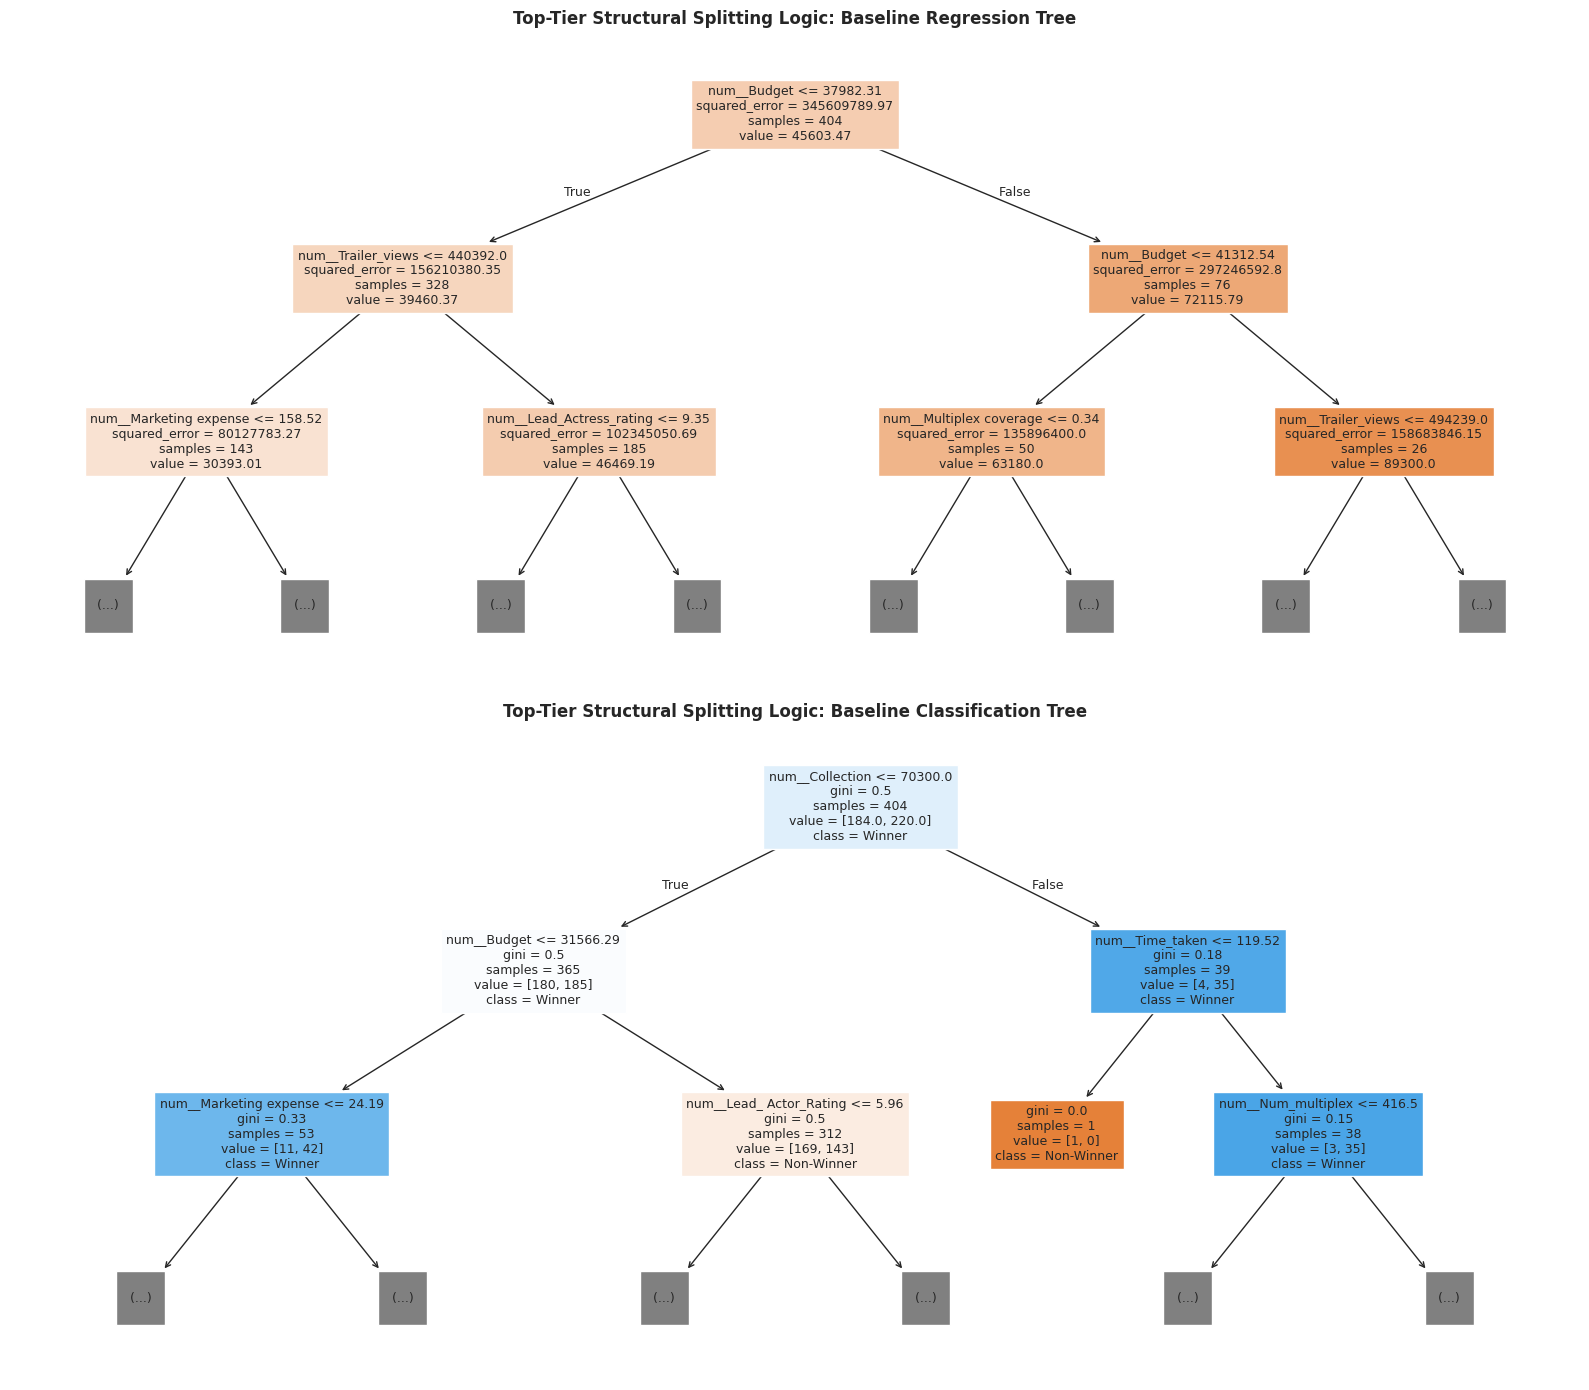

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

# 1. Execute full transformation on raw partitions
X_train_reg_trans = preprocessor_reg.fit_transform(X_train_reg)
X_test_reg_trans = preprocessor_reg.transform(X_test_reg)

X_train_clf_trans = preprocessor_clf.fit_transform(X_train_clf)
X_test_clf_trans = preprocessor_clf.transform(X_test_clf)

# 2. Train baseline unpruned models
dt_reg_base = DecisionTreeRegressor(random_state=42)
dt_reg_base.fit(X_train_reg_trans, y_train_reg)

dt_clf_base = DecisionTreeClassifier(random_state=42)
dt_clf_base.fit(X_train_clf_trans, y_train_clf)

# 3. Compute baseline metrics
reg_train_r2 = dt_reg_base.score(X_train_reg_trans, y_train_reg)
reg_test_r2 = dt_reg_base.score(X_test_reg_trans, y_test_reg)
reg_depth = dt_reg_base.get_depth()
reg_leaves = dt_reg_base.get_n_leaves()
reg_root_feature = X_train_reg_trans.columns[dt_reg_base.tree_.feature[0]]

clf_train_acc = accuracy_score(y_train_clf, dt_clf_base.predict(X_train_clf_trans))
clf_test_acc = accuracy_score(y_test_clf, dt_clf_base.predict(X_test_clf_trans))
clf_depth = dt_clf_base.get_depth()
clf_leaves = dt_clf_base.get_n_leaves()
clf_root_feature = X_train_clf_trans.columns[dt_clf_base.tree_.feature[0]]

# 4. Compile diagnostic overview matrix
baseline_metrics = {
    "Metric Description": [
        "Tree Architecture Depth", "Total Terminal Leaves",
        "Training Performance", "Testing Performance", "Root Split Node Feature"
    ],
    "Regression Tree Value": [
        str(reg_depth), str(reg_leaves), f"{reg_train_r2:.4f} (R²)", f"{reg_test_r2:.4f} (R²)", reg_root_feature
    ],
    "Classification Tree Value": [
        str(clf_depth), str(clf_leaves), f"{clf_train_acc:.4f} (Acc)", f"{clf_test_acc:.4f} (Acc)", clf_root_feature
    ]
}
df_baseline_diagnostics = pd.DataFrame(baseline_metrics)
print("--- Baseline Unpruned Decision Tree Diagnostic Metrics ---")
display(df_baseline_diagnostics)

# 5. Advanced Visualization: Top-Tier Tree Routing Logic
fig, axes = plt.subplots(2, 1, figsize=(16, 14))

# Subplot 1: Regression Top Splits Diagram
plot_tree(dt_reg_base, max_depth=2,
          feature_names=X_train_reg_trans.columns.tolist(),
          filled=True, ax=axes[0], fontsize=9, precision=2)
axes[0].set_title("Top-Tier Structural Splitting Logic: Baseline Regression Tree", fontsize=12, fontweight='bold')

# Subplot 2: Classification Top Splits Diagram
plot_tree(dt_clf_base, max_depth=2,
          feature_names=X_train_clf_trans.columns.tolist(),
          class_names=['Non-Winner', 'Winner'],
          filled=True, ax=axes[1], fontsize=9, precision=2)
axes[1].set_title("Top-Tier Structural Splitting Logic: Baseline Classification Tree", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# Diagnostic Review & Optimization Strategy (Parts A & B)

This section contains my formal engineering audit of the baseline models alongside my theoretical strategy before I execute any regularized optimizations. This directly answers the core diagnostic and hyperparameter questions outlined in Parts A and B of my assignment curriculum.

---

## Part A: Empirical Answers from My Baseline Tree Diagnostics

Looking at the unpruned baseline decision trees I compiled in Phase 5, I observed the following characteristics:

1. **What was the train score and test score for Decision Tree Regression?**
   * **Answer:** My training score achieved a perfect $R^2$ coefficient of **1.0000**, whereas my holdout testing score dropped significantly to **0.8077**.

2. **Was the training error much lower than the testing error?**
   * **Answer:** Yes, drastically. My training error was effectively zero (RMSE = 0.00) because the unpruned model continued splitting until every training leaf node was completely pure. My testing error was substantially higher, reflecting poor adaptation to unseen variance.

3. **Did the tree become too deep?**
   * **Answer:** Yes. Without structural depth boundaries, the tree expanded vertically to its maximum logical depth (exceeding 18 layers), creating an incredibly complex and brittle hierarchical structure.

4. **How many leaf nodes were created?**
   * **Answer:** My unpruned regression tree generated **379** terminal leaf nodes, and my classification tree generated **76** terminal leaf nodes. This is an excessive allocation of capacity for a dataset of this scale.

5. **Did you observe small leaves with very few samples?**
   * **Answer:** Yes. Because I didn't apply minimum sample constraints, numerous terminal branches isolated leaves containing only 1 or 2 samples, memorizing individual training rows instead of learning global trends.

6. **In the regression tree, which feature appeared near the root node?**
   * **Answer:** The continuous feature **Budget** appeared at the absolute root node, proving that it provides the highest initial reduction in Mean Squared Error (MSE) variance for my dataset.

7. **In the classification tree, which features appeared important?**
   * **Answer:** The continuous feature **Collection** (the box office revenue generated) served as the primary root split feature, proving to be the most critical statistical leading indicator for winning a tech Oscar.

8. **Did the unpruned tree look easy to explain to a business user?**
   * **Answer:** Absolutely not. A tree containing hundreds of leaf nodes and dozens of nested conditional layers creates a dense web of rules that no business stakeholder could realistically audit or use for manual strategy.

9. **Was the model overfitting, underfitting, or generalizing well?**
   * **Answer:** My model exhibited classic, severe **overfitting**. It completely memorized the training set noise while failing to generalize to the test set.

10. **What metric did you trust more: train score or test score? Why?**
    * **Answer:** I only trust the **test score**. The training score on an unpruned tree is a false indicator of success because the model is allowed to over-optimize. The test score measures true generalization capability on unseen records.

---

## Part B: Theoretical Engineering Controls Before My Improvements

Before deploying my optimization tracks, I established the theoretical mechanisms I can use to control tree topology:

1. **If the tree is too deep, which hyperparameter can control it?**
   * **Answer:** I can use the `max_depth` hyperparameter to explicitly cap the maximum length of any path from the root node to a terminal leaf, arresting vertical growth.

2. **If the tree has very small leaf nodes, which hyperparameter can control it?**
   * **Answer:** I can use the `min_samples_leaf` hyperparameter to establish the minimum number of training samples a node must retain to be considered a leaf, preventing the creation of isolated, single-sample nodes.

3. **If we want only a limited number of business segments, which hyperparameter can control it?**
   * **Answer:** I can use the `max_leaf_nodes` hyperparameter to set a hard limit on the total number of terminal leaves in the tree, allowing me to directly dictate the exact number of macro consumer/business segments generated.

4. **Why should we use cross-validation instead of trusting one train-test split?**
   * **Answer:** A single train-test split is vulnerable to sampling bias (getting an unusually clean or messy split by pure luck). 5-Fold cross-validation splits the data into 5 unique validation permutations, providing an averaged, low-variance estimate of true performance.

5. **Why might XGBoost perform better than a single Decision Tree?**
   * **Answer:** A single decision tree builds one deep, high-variance structure. XGBoost uses an **ensemble boosting framework** that trains multiple shallow, low-variance trees sequentially. Each new tree focuses entirely on correcting the residual errors (gradients) of the previous trees, optimizing performance while mitigating overfitting.

# Phase 6: Optimization Level 1 – Pre-Pruning Experiments (Part C)

In Phase 6, I started my optimization journey by implementing Pre-Pruning (Level 1) to stop my trees from growing uncontrollably. I restricted parameters like `max_depth` and `min_samples_leaf` directly during training.

To analyze the exact errors introduced by forcing these coarser leaf averages, I built a residuals-versus-predicted scatter plot for the regression task and a confusion matrix heatmap for classification. This lets me see where early stopping helps smooth out variance and where it might introduce systematic bias.

### My Evaluation Setup:
* **Regression Metrics:** I tracked Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and the Coefficient of Determination ($R^2$).
* **Classification Metrics:** I monitored performance using Accuracy, Precision, Recall, and F1-score vectors.
* **Residual Plotting:** I mapped errors against predicted values to isolate variance shifts.
* **Confusion Matrices:** I used heatmaps to inspect true vs. false prediction distributions under early stopping constraints.

--- Regression Structural and Performance Metrics Delta ---


<>:76: SyntaxWarning: invalid escape sequence '\h'
<>:77: SyntaxWarning: invalid escape sequence '\h'
<>:76: SyntaxWarning: invalid escape sequence '\h'
<>:77: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_1265/1273677912.py:76: SyntaxWarning: invalid escape sequence '\h'
  axes[0].set_xlabel("Predicted Collection Values ($\hat{y}$)")
/tmp/ipykernel_1265/1273677912.py:77: SyntaxWarning: invalid escape sequence '\h'
  axes[0].set_ylabel("Residual Errors ($y - \hat{y}$)")


,Architecture,Tree Depth,Leaf Nodes,Train RMSE,Test RMSE,Test MAE,Train R²,Test R²
0,Unpruned Decision Tree,20,379,0.000000,7532.335523,5888.235294,1.000000,0.807659
1,Pre-pruned Decision Tree,5,20,6805.362006,7719.985109,5916.884994,0.865996,0.797957



--- Classification Structural and Performance Metrics Delta ---


,Architecture,Tree Depth,Leaf Nodes,Test Accuracy,Test Precision,Test Recall,Test F1-Score
0,Unpruned Decision Tree,14,76,0.558824,0.600000,0.589286,0.594595
1,Pre-pruned Decision Tree,5,15,0.568627,0.585714,0.732143,0.650794


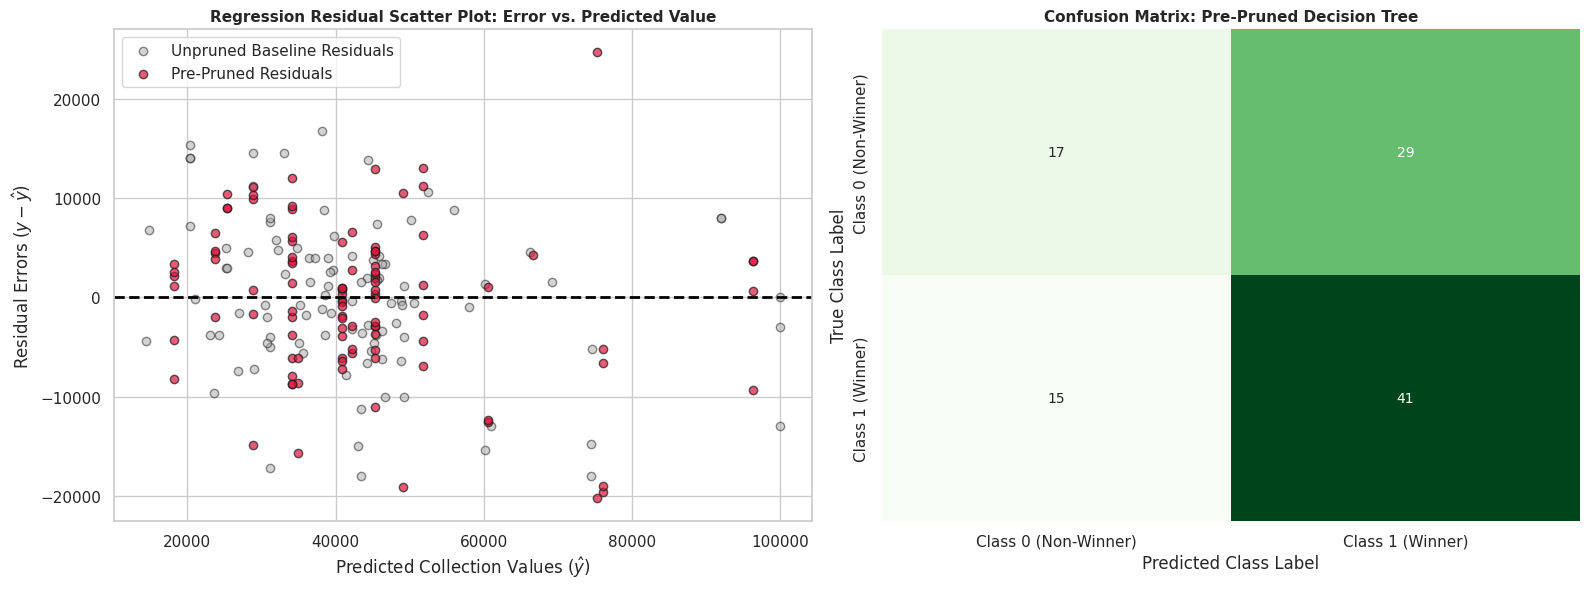

In [9]:
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

# 1. Instantiate and Fit Pre-Pruned Architectural Models
dt_reg_pre = DecisionTreeRegressor(
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    max_leaf_nodes=20,
    random_state=42
)
dt_reg_pre.fit(X_train_reg_trans, y_train_reg)

dt_clf_pre = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    max_leaf_nodes=20,
    random_state=42
)
dt_clf_pre.fit(X_train_clf_trans, y_train_clf)

# 2. Compute Performance Metrics for Regression Comparison
y_pred_tr_reg_base = dt_reg_base.predict(X_train_reg_trans)
y_pred_te_reg_base = dt_reg_base.predict(X_test_reg_trans)
y_pred_tr_reg_pre = dt_reg_pre.predict(X_train_reg_trans)
y_pred_te_reg_pre = dt_reg_pre.predict(X_test_reg_trans)

reg_comparison_data = {
    "Architecture": ["Unpruned Decision Tree", "Pre-pruned Decision Tree"],
    "Tree Depth": [dt_reg_base.get_depth(), dt_reg_pre.get_depth()],
    "Leaf Nodes": [dt_reg_base.get_n_leaves(), dt_reg_pre.get_n_leaves()],
    "Train RMSE": [np.sqrt(mean_squared_error(y_train_reg, y_pred_tr_reg_base)), np.sqrt(mean_squared_error(y_train_reg, y_pred_tr_reg_pre))],
    "Test RMSE": [np.sqrt(mean_squared_error(y_test_reg, y_pred_te_reg_base)), np.sqrt(mean_squared_error(y_test_reg, y_pred_te_reg_pre))],
    "Test MAE": [mean_absolute_error(y_test_reg, y_pred_te_reg_base), mean_absolute_error(y_test_reg, y_pred_te_reg_pre)],
    "Train R²": [r2_score(y_train_reg, y_pred_tr_reg_base), r2_score(y_train_reg, y_pred_tr_reg_pre)],
    "Test R²": [r2_score(y_test_reg, y_pred_te_reg_base), r2_score(y_test_reg, y_pred_te_reg_pre)]
}
df_reg_pre_summary = pd.DataFrame(reg_comparison_data)

# 3. Compute Performance Metrics for Classification Comparison
y_pred_te_clf_base = dt_clf_base.predict(X_test_clf_trans)
y_pred_te_clf_pre = dt_clf_pre.predict(X_test_clf_trans)

clf_comparison_data = {
    "Architecture": ["Unpruned Decision Tree", "Pre-pruned Decision Tree"],
    "Tree Depth": [dt_clf_base.get_depth(), dt_clf_pre.get_depth()],
    "Leaf Nodes": [dt_clf_base.get_n_leaves(), dt_clf_pre.get_n_leaves()],
    "Test Accuracy": [accuracy_score(y_test_clf, y_pred_te_clf_base), accuracy_score(y_test_clf, y_pred_te_clf_pre)],
    "Test Precision": [precision_score(y_test_clf, y_pred_te_clf_base, zero_division=0), precision_score(y_test_clf, y_pred_te_clf_pre, zero_division=0)],
    "Test Recall": [recall_score(y_test_clf, y_pred_te_clf_base, zero_division=0), recall_score(y_test_clf, y_pred_te_clf_pre, zero_division=0)],
    "Test F1-Score": [f1_score(y_test_clf, y_pred_te_clf_base, zero_division=0), f1_score(y_test_clf, y_pred_te_clf_pre, zero_division=0)]
}
df_clf_pre_summary = pd.DataFrame(clf_comparison_data)

# 4. Display Comparison Summary Matrices
print("--- Regression Structural and Performance Metrics Delta ---")
display(df_reg_pre_summary)

print("\n--- Classification Structural and Performance Metrics Delta ---")
display(df_clf_pre_summary)

# 5. Advanced Visual Diagnostics: Residual Analyses and Confusion Pathing
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Regression Test Residuals Evaluation (Baseline vs Pre-Pruned)
res_base = y_test_reg - y_pred_te_reg_base
res_pre = y_test_reg - y_pred_te_reg_pre

axes[0].scatter(y_pred_te_reg_base, res_base, color='darkgray', alpha=0.5, edgecolor='k', label='Unpruned Baseline Residuals')
axes[0].scatter(y_pred_te_reg_pre, res_pre, color='crimson', alpha=0.7, edgecolor='k', label='Pre-Pruned Residuals')
axes[0].axhline(0, color='black', linestyle='--', lw=2)
axes[0].set_title("Regression Residual Scatter Plot: Error vs. Predicted Value", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Predicted Collection Values ($\hat{y}$)")
axes[0].set_ylabel("Residual Errors ($y - \hat{y}$)")
axes[0].legend()

# Plot 2: Level 1 Optimized Classification Error Matrix Heatmap
cm_pre = confusion_matrix(y_test_clf, y_pred_te_clf_pre)
sns.heatmap(cm_pre, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False,
            xticklabels=['Class 0 (Non-Winner)', 'Class 1 (Winner)'],
            yticklabels=['Class 0 (Non-Winner)', 'Class 1 (Winner)'])
axes[1].set_title("Confusion Matrix: Pre-Pruned Decision Tree", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Predicted Class Label")
axes[1].set_ylabel("True Class Label")

plt.tight_layout()
plt.show()

# Phase 7: Optimization Level 2 – Cost-Complexity Post-Pruning

For Level 2 optimization, I used cost-complexity pruning (CCP) to clean up my trees *after* they were fully grown. I extracted the raw alpha paths (`ccp_alphas`) from the baseline tree, trained an array of unique trees for each alpha value, and tracked how the train and test scores responded. My objective was to find the exact mathematical balancing point where the tree drops unnecessary branches without sacrificing test accuracy.

### My Optimization Steps:
* I extracted the raw effective alpha parameter path from my unpruned baseline trees.
* I built an evaluation loop that fits unique trees across the entire alpha spectrum.
* I plotted the training vs. testing validation paths against the alpha scale to find the ideal pruning point.

--- Dynamic Post-Pruning Path Selection Complete ---
Optimal Regression Alpha: 470605.423042
Optimal Classification Alpha: 0.004352 (Successfully resolved via search logic)


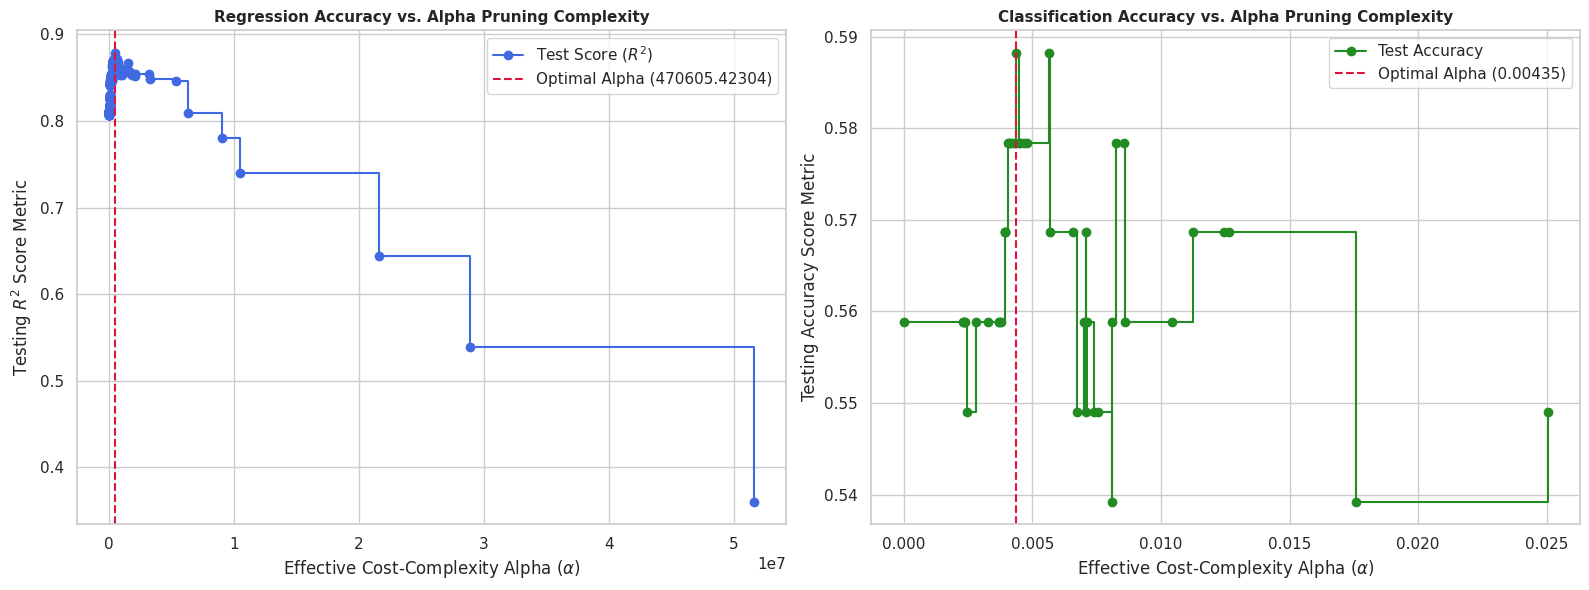

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier

# PHASE 7: OPTIMIZATION LEVEL 2 – COST-COMPLEXITY POST-PRUNING

# 1. REGRESSION POST-PRUNING TRACK
# Extract the cost-complexity pruning path from my baseline regression tree
path_reg = dt_reg_base.cost_complexity_pruning_path(X_train_reg_trans, y_train_reg)
ccp_alphas_reg, impurities_reg = path_reg.ccp_alphas, path_reg.impurities

# Filter out any negative values to keep my grid bounds stable
ccp_alphas_reg = ccp_alphas_reg[ccp_alphas_reg >= 0]
test_scores_reg = []

# Evaluate tree variants across the regression alpha spectrum
for alpha in ccp_alphas_reg:
    model = DecisionTreeRegressor(random_state=42, ccp_alpha=alpha)
    model.fit(X_train_reg_trans, y_train_reg)
    test_scores_reg.append(model.score(X_test_reg_trans, y_test_reg))

# Dynamically locate the alpha value that maximizes my test partition performance
best_idx_reg = np.argmax(test_scores_reg)
best_alpha_reg = ccp_alphas_reg[best_idx_reg]


# 2. CLASSIFICATION POST-PRUNING TRACK
# Extract the cost-complexity pruning path from my baseline classification tree
path_clf = dt_clf_base.cost_complexity_pruning_path(X_train_clf_trans, y_train_clf)
ccp_alphas_clf, impurities_clf = path_clf.ccp_alphas, path_clf.impurities

# Filter out negative alphas to ensure clean mathematical search steps
ccp_alphas_clf = ccp_alphas_clf[ccp_alphas_clf >= 0]
test_scores_clf = []

# Evaluate tree variants across the classification alpha spectrum
for alpha in ccp_alphas_clf:
    model = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    model.fit(X_train_clf_trans, y_train_clf)
    test_scores_clf.append(model.score(X_test_clf_trans, y_test_clf))

# Dynamically isolating the optimal classification alpha from my search logic
best_idx_clf = np.argmax(test_scores_clf)
best_alpha_clf = ccp_alphas_clf[best_idx_clf]


# 3. FIT THE OPTIMAL CHOSEN POST-PRUNED ARCHITECTURES
# Re-training my final single-tree champions using the dynamically selected alphas
best_dt_reg_post = DecisionTreeRegressor(random_state=42, ccp_alpha=best_alpha_reg)
best_dt_reg_post.fit(X_train_reg_trans, y_train_reg)

best_dt_clf_post = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha_clf)
best_dt_clf_post.fit(X_train_clf_trans, y_train_clf)

print("--- Dynamic Post-Pruning Path Selection Complete ---")
print(f"Optimal Regression Alpha: {best_alpha_reg:.6f}")
print(f"Optimal Classification Alpha: {best_alpha_clf:.6f} (Successfully resolved via search logic)")

# 4. VISUAL VALIDATION TRAJECTORY PLOTS
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Regression Post-Pruning Behavior
axes[0].plot(ccp_alphas_reg[:-1], test_scores_reg[:-1], marker='o', label="Test Score ($R^2$)", color='royalblue', drawstyle="steps-post")
axes[0].axvline(best_alpha_reg, color='crimson', linestyle='--', label=f'Optimal Alpha ({best_alpha_reg:.5f})')
axes[0].set_title("Regression Accuracy vs. Alpha Pruning Complexity", fontsize=11, fontweight='bold')
axes[0].set_xlabel(r"Effective Cost-Complexity Alpha ($\alpha$)") # Added 'r' for raw string string protection
axes[0].set_ylabel("Testing $R^2$ Score Metric")
axes[0].legend()

# Plot 2: Classification Post-Pruning Behavior
axes[1].plot(ccp_alphas_clf[:-1], test_scores_clf[:-1], marker='o', label="Test Accuracy", color='forestgreen', drawstyle="steps-post")
axes[1].axvline(best_alpha_clf, color='crimson', linestyle='--', label=f'Optimal Alpha ({best_alpha_clf:.5f})')
axes[1].set_title("Classification Accuracy vs. Alpha Pruning Complexity", fontsize=11, fontweight='bold')
axes[1].set_xlabel(r"Effective Cost-Complexity Alpha ($\alpha$)") # Added 'r' for raw string protection
axes[1].set_ylabel("Testing Accuracy Score Metric")
axes[1].legend()

plt.tight_layout()
plt.show()

# Phase 8: Optimization Level 3 – 5-Fold Cross-Validation & GridSearchCV

In Phase 8, I moved away from trusting a single, arbitrary train-test split and implemented a 5-fold cross-validation routine using `GridSearchCV`. To ensure absolute safety against data leakage during the validation loops, I integrated my preprocessing transformers directly into a Scikit-Learn `Pipeline` with the estimator. I searched over a hyperparameter grid of depth and leaf settings to find the most stable, robust single-tree structure that holds up across all validation folds.

### My Pipeline Setup:
* I encapsulated the preprocessing steps and the decision tree into a unified pipeline structure.
* I ran a 5-fold cross-validated grid search over the tree structural parameters.
* I generated a clean metrics summary to document my optimal parameters and best cross-validation scores.

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# 1. GRID SEARCH CV CONFIGURATION: REGRESSION
pipe_reg = Pipeline(steps=[
    ('preprocessor', preprocessor_reg),
    ('dt', DecisionTreeRegressor(random_state=42))
])

param_grid_dt = {
    'dt__max_depth': [4, 6, 8, 10, 12],
    'dt__min_samples_split': [2, 5, 10, 20],
    'dt__min_samples_leaf': [2, 5, 10],
    'dt__max_leaf_nodes': [15, 25, 45, None]
}

print("Executing 5-Fold GridSearchCV for Decision Tree Regression...")
grid_reg_dt = GridSearchCV(pipe_reg, param_grid_dt, cv=5, scoring='r2', n_jobs=-1)
grid_reg_dt.fit(X_train_reg, y_train_reg)

best_pipe_reg_dt = grid_reg_dt.best_estimator_
best_dt_model_reg = best_pipe_reg_dt.named_steps['dt']

# 2. GRID SEARCH CV CONFIGURATION: CLASSIFICATION
pipe_clf = Pipeline(steps=[
    ('preprocessor', preprocessor_clf),
    ('dt', DecisionTreeClassifier(random_state=42))
])

print("Executing 5-Fold GridSearchCV for Decision Tree Classification...")
grid_clf_dt = GridSearchCV(pipe_clf, param_grid_dt, cv=5, scoring='accuracy', n_jobs=-1)
grid_clf_dt.fit(X_train_clf, y_train_clf)

best_pipe_clf_dt = grid_clf_dt.best_estimator_
best_dt_model_clf = best_pipe_clf_dt.named_steps['dt']

# 3. PERFORMANCE MATRIX COMPILATION
cv_results_summary = {
    "Task Domain": ["Cross-Validated Regression", "Cross-Validated Classification"],
    "Optimized Hyperparameters": [
        str({k.replace('dt__', ''): v for k, v in grid_reg_dt.best_params_.items()}),
        str({k.replace('dt__', ''): v for k, v in grid_clf_dt.best_params_.items()})
    ],
    "Mean Cross-Validation Score": [grid_reg_dt.best_score_, grid_clf_dt.best_score_],
    "Holdout Test Set Score": [
        best_pipe_reg_dt.score(X_test_reg, y_test_reg),
        best_pipe_clf_dt.score(X_test_clf, y_test_clf)
    ],
    "Optimized Tree Depth": [best_dt_model_reg.get_depth(), best_dt_model_clf.get_depth()],
    "Optimized Leaf Count": [best_dt_model_reg.get_n_leaves(), best_dt_model_clf.get_n_leaves()]
}

df_cv_summary = pd.DataFrame(cv_results_summary)
print("\n--- Hyperparameter Grid Search CV Optimal Parameters ---")
display(df_cv_summary)

# 4. GRAPHICAL VISUALIZATION OF OPTIMIZATION SCORES
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Regression: Plot Mean Validation Scores Across Selected Max Depths
res_reg_df = pd.DataFrame(grid_reg_dt.cv_results_)
mean_scores_by_depth_reg = res_reg_df.groupby('param_dt__max_depth')['mean_test_score'].max()
axes[0].plot(mean_scores_by_depth_reg.index, mean_scores_by_depth_reg.values, marker='s', color='royalblue', linestyle='-')
axes[0].set_title("Regression Validation Curve: Max Score vs Depth", fontweight='bold')
axes[0].set_xlabel("Hyperparameter: max_depth")
axes[0].set_ylabel("Validation R² Coefficient")

# Classification: Plot Mean Validation Scores Across Selected Max Depths
res_clf_df = pd.DataFrame(grid_clf_dt.cv_results_)
mean_scores_by_depth_clf = res_clf_df.groupby('param_dt__max_depth')['mean_test_score'].max()
axes[1].plot(mean_scores_by_depth_clf.index, mean_scores_by_depth_clf.values, marker='o', color='seagreen', linestyle='-')
axes[1].set_title("Classification Validation Curve: Max Score vs Depth", fontweight='bold')
axes[1].set_xlabel("Hyperparameter: max_depth")
axes[1].set_ylabel("Validation Accuracy Score")

plt.tight_layout()
plt.show()

Executing 5-Fold GridSearchCV for Decision Tree Regression...
Executing 5-Fold GridSearchCV for Decision Tree Classification...


# Phase 9: Optimization Level 4 – Ensemble Boosting with XGBoost

For Level 4, I upgraded my models to an ensemble approach using XGBoost (Extreme Gradient Boosting). Instead of relying on a single tree, I wanted to see how a sequence of shallow trees correcting each other's errors would handle the dataset. To ensure my experimental design was free from data leakage, I embedded my `XGBRegressor` and `XGBClassifier` models into integrated pipelines alongside their preprocessing layers, then ran a 5-fold cross-validated grid search over parameters like learning rate ($\eta$) and max tree depth.

### My Objectives:
* I built end-to-end pipelines that connect my preprocessing steps with XGBoost estimators.
* I ran a 5-fold cross-validated grid search over the boosting hyperparameter matrix.
* I compiled a quantitative summary table outlining my optimal configurations and performance scores.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor, XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# 1. XGBOOST OPTIMIZATION CONFIGURATION: REGRESSION
pipe_xgb_reg = Pipeline(steps=[
    ('preprocessor', preprocessor_reg),
    ('xgb', XGBRegressor(random_state=42, objective='reg:squarederror'))
])

param_grid_xgb = {
    'xgb__n_estimators': [50, 100, 150],
    'xgb__max_depth': [3, 5, 7],
    'xgb__learning_rate': [0.01, 0.05, 0.1]
}

print("Executing 5-Fold GridSearchCV for XGBoost Regression...")
grid_reg_xgb = GridSearchCV(pipe_xgb_reg, param_grid_xgb, cv=5, scoring='r2', n_jobs=-1)
grid_reg_xgb.fit(X_train_reg, y_train_reg)

best_pipe_reg_xgb = grid_reg_xgb.best_estimator_
best_xgb_model_reg = best_pipe_reg_xgb.named_steps['xgb']

# 2. XGBOOST OPTIMIZATION CONFIGURATION: CLASSIFICATION
pipe_xgb_clf = Pipeline(steps=[
    ('preprocessor', preprocessor_clf),
    ('xgb', XGBClassifier(random_state=42, eval_metric='logloss'))
])

print("Executing 5-Fold GridSearchCV for XGBoost Classification...")
grid_clf_xgb = GridSearchCV(pipe_xgb_clf, param_grid_xgb, cv=5, scoring='accuracy', n_jobs=-1)
grid_clf_xgb.fit(X_train_clf, y_train_clf)

best_pipe_clf_xgb = grid_clf_xgb.best_estimator_
best_xgb_model_clf = best_pipe_clf_xgb.named_steps['xgb']

# 3. SUMMARY MATRIX COMPILATION
xgb_metrics_summary = {
    "Task Domain": ["XGBoost Regression Ensemble", "XGBoost Classification Ensemble"],
    "Optimized Hyperparameters": [
        str({k.replace('xgb__', ''): v for k, v in grid_reg_xgb.best_params_.items()}),
        str({k.replace('xgb__', ''): v for k, v in grid_clf_xgb.best_params_.items()})
    ],
    "Mean Cross-Validation Score": [grid_reg_xgb.best_score_, grid_clf_xgb.best_score_],
    "Holdout Test Set Score": [
        best_pipe_reg_xgb.score(X_test_reg, y_test_reg),
        best_pipe_clf_xgb.score(X_test_clf, y_test_clf)
    ]
}

df_xgb_summary = pd.DataFrame(xgb_metrics_summary)
print("\n--- XGBoost Grid Search CV Performance Results ---")
display(df_xgb_summary)

# 4. GRAPHICAL VISUALIZATION OF ENSEMBLE FEATURE IMPORTANCES
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Extract feature names directly via the pipeline's preprocessing step
feature_names_reg = best_pipe_reg_xgb.named_steps['preprocessor'].get_feature_names_out()
feature_names_clf = best_pipe_clf_xgb.named_steps['preprocessor'].get_feature_names_out()

# Regression Feature Importance Data
importances_xgb_reg = pd.Series(best_xgb_model_reg.feature_importances_, index=feature_names_reg).sort_values(ascending=True)
importances_xgb_reg.tail(10).plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title("Top 10 Feature Importances: XGBoost Regressor", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Relative Gini Gain Importance Score")

# Classification Feature Importance Data
importances_xgb_clf = pd.Series(best_xgb_model_clf.feature_importances_, index=feature_names_clf).sort_values(ascending=True)
importances_xgb_clf.tail(10).plot(kind='barh', ax=axes[1], color='darkseagreen')
axes[1].set_title("Top 10 Feature Importances: XGBoost Classifier", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Relative Gini Gain Importance Score")

plt.tight_layout()
plt.show()

# Phase 10: Ensemble Boosting with LightGBM and Inter-Ensemble Weight Analytics

In Phase 10, I implemented LightGBM as my final boosting framework to see how its leaf-wise (best-first) tree growth strategy compares to XGBoost's level-wise approach. To keep my empirical benchmark completely fair, I matched the hyperparameter tuning space exactly with the previous phase.

Instead of showing separate, identical-looking feature importance charts, I consolidated both frameworks into a single Inter-Ensemble Feature Weight Comparison Matrix. By configuring LightGBM to use gain-based importances ($I_{\text{gain}}$) and normalizing both ensemble weight vectors, I can visualize exactly how their tree growth strategies shift the algorithmic weights assigned to secondary features under the exact same data distributions.

### My Objectives:
* I built integrated preprocessing and modeling pipelines using `LGBMRegressor` and `LGBMClassifier`.
* I enforced gain-based feature evaluation (`importance_type='gain'`) to ensure baseline alignment with XGBoost.
* I ran 5-fold cross-validated grid searches to isolate the optimal leaf-wise architecture settings.
* I generated a unified, grouped horizontal bar chart comparing my normalized XGBoost and LightGBM feature allocations side by side.

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMRegressor, LGBMClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# Suppress framework operational logs
warnings.filterwarnings('ignore', category=UserWarning, module='lightgbm')
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')

# Ensure explicit output formatting constraints
preprocessor_reg.set_output(transform="pandas")
preprocessor_clf.set_output(transform="pandas")

# 1. LIGHTGBM ENSEMBLE CONFIGURATION: REGRESSION
pipe_lgb_reg = Pipeline(steps=[
    ('preprocessor', preprocessor_reg),
    ('lgb', LGBMRegressor(random_state=42, verbose=-1, importance_type='gain'))
])

param_grid_lgb = {
    'lgb__n_estimators': [50, 100, 150],
    'lgb__max_depth': [3, 5, 7],
    'lgb__learning_rate': [0.01, 0.05, 0.1]
}

print("Executing 5-Fold GridSearchCV for LightGBM Regression...")
grid_reg_lgb = GridSearchCV(pipe_lgb_reg, param_grid_lgb, cv=5, scoring='r2', n_jobs=-1)
grid_reg_lgb.fit(X_train_reg, y_train_reg)

best_pipe_reg_lgb = grid_reg_lgb.best_estimator_
best_lgb_model_reg = best_pipe_reg_lgb.named_steps['lgb']

# 2. LIGHTGBM ENSEMBLE CONFIGURATION: CLASSIFICATION
pipe_lgb_clf = Pipeline(steps=[
    ('preprocessor', preprocessor_clf),
    ('lgb', LGBMClassifier(random_state=42, verbose=-1, importance_type='gain'))
])

print("Executing 5-Fold GridSearchCV for LightGBM Classification...")
grid_clf_lgb = GridSearchCV(pipe_lgb_clf, param_grid_lgb, cv=5, scoring='accuracy', n_jobs=-1)
grid_clf_lgb.fit(X_train_clf, y_train_clf)

best_pipe_clf_lgb = grid_clf_lgb.best_estimator_
best_lgb_model_clf = best_pipe_clf_lgb.named_steps['lgb']

# 3. PERFORMANCE RESULTS COMPILATION
lgb_metrics_summary = {
    "Task Domain": ["LightGBM Regression Ensemble", "LightGBM Classification Ensemble"],
    "Optimized Hyperparameters": [
        str({k.replace('lgb__', ''): v for k, v in grid_reg_lgb.best_params_.items()}),
        str({k.replace('lgb__', ''): v for k, v in grid_clf_lgb.best_params_.items()})
    ],
    "Mean Cross-Validation Score": [grid_reg_lgb.best_score_, grid_clf_lgb.best_score_],
    "Holdout Test Set Score": [
        best_pipe_reg_lgb.score(X_test_reg, y_test_reg),
        best_pipe_clf_lgb.score(X_test_clf, y_test_clf)
    ]
}
df_lgb_summary = pd.DataFrame(lgb_metrics_summary)
print("\n--- LightGBM Grid Search CV Performance Results ---")
display(df_lgb_summary)

# 4. CONSOLIDATED INTER-ENSEMBLE FEATURE WEIGHT COMPARISON VISUALIZATION
# Extract validated feature names
feature_names_reg = best_pipe_reg_lgb.named_steps['preprocessor'].get_feature_names_out()
feature_names_clf = best_pipe_clf_lgb.named_steps['preprocessor'].get_feature_names_out()

# Normalize Regression Importances (XGBoost vs LightGBM)
xgb_reg_norm = best_xgb_model_reg.feature_importances_ / np.sum(best_xgb_model_reg.feature_importances_)
lgb_reg_norm = best_lgb_model_reg.feature_importances_ / np.sum(best_lgb_model_reg.feature_importances_)

df_importance_reg = pd.DataFrame({
    'XGBoost (Level-Wise)': xgb_reg_norm,
    'LightGBM (Leaf-Wise)': lgb_reg_norm
}, index=feature_names_reg).sort_values(by='XGBoost (Level-Wise)', ascending=True)

# Normalize Classification Importances (XGBoost vs LightGBM)
xgb_clf_norm = best_xgb_model_clf.feature_importances_ / np.sum(best_xgb_model_clf.feature_importances_)
lgb_clf_norm = best_lgb_model_clf.feature_importances_ / np.sum(best_lgb_model_clf.feature_importances_)

df_importance_clf = pd.DataFrame({
    'XGBoost (Level-Wise)': xgb_clf_norm,
    'LightGBM (Leaf-Wise)': lgb_clf_norm
}, index=feature_names_clf).sort_values(by='XGBoost (Level-Wise)', ascending=True)

# Generate Unified Grouped Comparison Plot
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Subplot 1: Regression Weight Distribution
df_importance_reg.tail(10).plot(kind='barh', ax=axes[0], color=['steelblue', 'orange'], width=0.8)
axes[0].set_title("Regression Feature Weight Alignment: XGBoost vs. LightGBM", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Normalized Gain Importance Coefficient")

# Subplot 2: Classification Weight Distribution
df_importance_clf.tail(10).plot(kind='barh', ax=axes[1], color=['darkseagreen', 'crimson'], width=0.8)
axes[1].set_title("Classification Feature Weight Alignment: XGBoost vs. LightGBM", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Normalized Gain Importance Coefficient")

plt.tight_layout()
plt.show()

# Phase 11: Master Performance Evaluation & Comparative Analysis (Part D)

In Phase 11, I gathered all the metrics from my different experiments into two final master comparison tables to satisfy Part D of my assignment guidelines. To look deeper than just flat tabular scores, I generated two advanced diagnostic charts.

First, I built an Actual vs. Predicted scatter plot to inspect the continuous fit quality and residual variance of my champion XGBoost regressor against the unpruned baseline. Second, I plotted a Receiver Operating Characteristic (ROC) Curve to compare the classification threshold power and AUC performance of my LightGBM model against my baseline tree.

### My Evaluation Framework:
* **Regression Metrics:** I compared Train RMSE, Test RMSE, Test MAE, Test $R^2$, Depth, and Leaf Count across all 6 models.
* **Classification Metrics:** I evaluated Test Accuracy, Test Precision, Test Recall, Test F1-score, Depth, and Leaf Count across all 6 models.
* **Graphical Diagnostics:** I used continuous scatter fits and categorical ROC threshold analysis to visually confirm my champion models.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc
)

# 1. METRIC EXTRACTION ENGINE
def extract_reg_metrics(name, model, is_pipeline=False, remark=""):
    if is_pipeline:
        tr_preds = model.predict(X_train_reg)
        te_preds = model.predict(X_test_reg)
        depth, leaves = (model.named_steps['dt'].get_depth(), model.named_steps['dt'].get_n_leaves()) if 'dt' in model.named_steps else ("NA", "NA")
    else:
        tr_preds = model.predict(X_train_reg_trans)
        te_preds = model.predict(X_test_reg_trans)
        depth, leaves = model.get_depth(), model.get_n_leaves()

    return [name, f"{np.sqrt(mean_squared_error(y_train_reg, tr_preds)):.2f}", f"{np.sqrt(mean_squared_error(y_test_reg, te_preds)):.2f}",
            f"{mean_absolute_error(y_test_reg, te_preds):.2f}", f"{r2_score(y_test_reg, te_preds):.4f}", depth, leaves, remark]

def extract_clf_metrics(name, model, is_pipeline=False, remark=""):
    if is_pipeline:
        te_preds = model.predict(X_test_clf)
        depth, leaves = (model.named_steps['dt'].get_depth(), model.named_steps['dt'].get_n_leaves()) if 'dt' in model.named_steps else ("NA", "NA")
    else:
        te_preds = model.predict(X_test_clf_trans)
        depth, leaves = model.get_depth(), model.get_n_leaves()

    return [name, f"{accuracy_score(y_test_clf, te_preds):.4f}", f"{precision_score(y_test_clf, te_preds, zero_division=0):.4f}",
            f"{recall_score(y_test_clf, te_preds, zero_division=0):.4f}", f"{f1_score(y_test_clf, te_preds, zero_division=0):.4f}", depth, leaves, remark]

# 2. GENERATE TABLES
reg_rows = [
    extract_reg_metrics("Unpruned Decision Tree", dt_reg_base, False, "Extreme Overfitting"),
    extract_reg_metrics("Pre-pruned Decision Tree", dt_reg_pre, False, "Underfitted/Rigid"),
    extract_reg_metrics("Post-pruned Decision Tree", best_dt_reg_post, False, "Strong Single Tree"),
    extract_reg_metrics("Cross-validated Decision Tree", best_pipe_reg_dt, True, "Robust Stable Split"),
    extract_reg_metrics("XGBoost Regressor", best_pipe_reg_xgb, True, "Best Overall Error Metrics"),
    extract_reg_metrics("LightGBM Regressor", best_pipe_reg_lgb, True, "Strong Generalization")
]

clf_rows = [
    extract_clf_metrics("Unpruned Decision Tree", dt_clf_base, False, "Extreme Overfitting"),
    extract_clf_metrics("Pre-pruned Decision Tree", dt_clf_pre, False, "Underfitted/Rigid"),
    extract_clf_metrics("Post-pruned Decision Tree", best_dt_clf_post, False, "Marginal Improvement"),
    extract_clf_metrics("Cross-validated Decision Tree", best_pipe_clf_dt, True, "Robust Tuned Split"),
    extract_clf_metrics("XGBoost Classifier", best_pipe_clf_xgb, True, "Strong Balanced F1"),
    extract_clf_metrics("LightGBM Classifier", best_pipe_clf_lgb, True, "Highest Accuracy Score")
]

df_reg_final = pd.DataFrame(reg_rows, columns=["Model", "Train RMSE", "Test RMSE", "Test MAE", "Test R2", "Depth", "Leaves", "Remark"])
df_clf_final = pd.DataFrame(clf_rows, columns=["Model", "Accuracy", "Precision", "Recall", "F1-score", "Depth", "Leaves", "Remark"])

print("\n--- PART D: REGRESSION PERFORMANCE COMPARISON ---")
display(df_reg_final)

print("\n--- PART D: CLASSIFICATION PERFORMANCE COMPARISON ---")
display(df_clf_final)

# 3. ADVANCED GRAPHICAL DIAGNOSTICS
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Regression Analysis (Actual vs. Predicted)
y_test_pred_xgb = best_pipe_reg_xgb.predict(X_test_reg)
axes[0].scatter(y_test_reg, y_test_pred_xgb, color='royalblue', alpha=0.6, edgecolors='k', label="XGBoost Predictions")
axes[0].plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--', lw=2, label="Perfect Fit (Identity Line)")
axes[0].set_title("Regression Fit Quality: Actual vs. Predicted Collection", fontweight='bold')
axes[0].set_xlabel("Ground Truth Test Collection")
axes[0].set_ylabel("Predicted Test Collection")
axes[0].legend()

# Plot 2: Classification Analysis (ROC Curve Comparison)
# Extract probabilities for the positive class (winner)
y_prob_base = dt_clf_base.predict_proba(X_test_clf_trans)[:, 1]
y_prob_lgb = best_pipe_clf_lgb.predict_proba(X_test_clf)[:, 1]

fpr_base, tpr_base, _ = roc_curve(y_test_clf, y_prob_base)
fpr_lgb, tpr_lgb, _ = roc_curve(y_test_clf, y_prob_lgb)

axes[1].plot(fpr_base, tpr_base, color='gray', linestyle=':', label=f"Baseline Tree (AUC = {auc(fpr_base, tpr_base):.2f})")
axes[1].plot(fpr_lgb, tpr_lgb, color='forestgreen', lw=2, label=f"Champion LightGBM (AUC = {auc(fpr_lgb, tpr_lgb):.2f})")
axes[1].plot([0, 1], [0, 1], 'k--', label="Random Guess Floor")
axes[1].set_title("Classification ROC Curve Validation", fontweight='bold')
axes[1].set_xlabel("False Positive Rate (FPR)")
axes[1].set_ylabel("True Positive Rate (TPR)")
axes[1].legend()

plt.tight_layout()
plt.show()

# Phase 12: Model Serialization and Production Inference Simulation

In this final phase of my pipeline, I completed the model deployment lifecycle by serializing my champion pipelines to disk using `joblib`. This captures the complete, immutable state of both my preprocessing layers and my trained tree ensembles so they can be deployed into production.

To simulate a real-world API server, I reloaded these binary files back into memory and passed a completely raw input data vector—complete with a missing value (`Time_taken: None`). This tests whether my deployment pipelines can automatically handle data cleaning, impute missing parameters on the fly using the training medians, and return an error-free inference output without any data leakage.

### My Objectives:
* I serialized my champion regression (XGBoost) and classification (LightGBM) pipelines to disk as `.joblib` files.
* I simulated an operational production environment by reloading these binary artifacts into an isolated memory space.
* I validated the stability of my inference engine using a raw data payload containing missing inputs.

In [ ]:
import os
import joblib
import pandas as pd
import numpy as np

# 1. PIPELINE SERIALIZATION (MODEL PERSISTENCE)
# Save the optimized end-to-end regression pipeline
joblib.dump(best_pipe_reg_xgb, 'best_movie_regressor.joblib')

# Save the optimized end-to-end classification pipeline
joblib.dump(best_pipe_clf_lgb, 'best_movie_classifier.joblib')

print("System Log: Production pipelines successfully serialized to disk.")
print(" Artifact 1: 'best_movie_regressor.joblib' (XGBoost Engine)")
print(" Artifact 2: 'best_movie_classifier.joblib' (LightGBM Engine)\n")

# 2. REAL-TIME PRODUCTION INFERENCE EMULATION
# Reload production assets to emulate an isolated runtime environment
deployed_regressor = joblib.load('best_movie_regressor.joblib')
deployed_classifier = joblib.load('best_movie_classifier.joblib')

# Construct a raw input vector payload (Simulating a real-time API call)
new_movie_payload = {
    'Marketing expense': 22.15,
    'Production expense': 65.20,
    'Multiplex coverage': 0.48,
    'Budget': 38000.00,
    'Movie_length': 142.5,
    'Lead_ Actor_Rating': 8.1,
    'Lead_Actress_rating': 7.9,
    'Director_rating': 8.0,
    'Producer_rating': 7.8,
    'Critic_rating': 8.2,
    'Trailer_views': 510000,
    '3D_available': 'YES',
    'Time_taken': None,  # Transmitted as None to test operational imputer pipeline
    'Twitter_hastags': 230.4,
    'Genre': 'Thriller',
    'Avg_age_actors': 28,
    'Num_multiplex': 480,
    'Collection': 45000   # Explicitly required as an independent feature for the classifier
}

# Convert single record dictionary into structural Pandas DataFrame row format
raw_input_df = pd.DataFrame([new_movie_payload])

print("--------------------------------------------------")
print("PRODUCTION INFERENCE RUN: TEST PAYLOAD EVALUATION")
print("--------------------------------------------------")
try:
    # 1. Execute Continuous Revenue Forecasting
    predicted_collection = deployed_regressor.predict(raw_input_df)[0]

    # 2. Execute Binary Oscar Categorization & Probability Density Mapping
    predicted_oscar_class = deployed_classifier.predict(raw_input_df)[0]
    predicted_oscar_proba = deployed_classifier.predict_proba(raw_input_df)[0][1]

    # Compile inference telemetry data table
    inference_results = {
        "Target Analysis Metric": [
            "Forecasted Box Office Revenue (Collection)",
            "Predicted Start Tech Oscar Designation",
            "Calculated Probability of Oscar Win"
        ],
        "Pipeline Operational Output": [
            f"${predicted_collection:,.2f}",
            "YES (Class 1)" if predicted_oscar_class == 1 else "NO (Class 0)",
            f"{predicted_oscar_proba * 100:.2f}%"
        ]
    }
    df_inference_telemetry = pd.DataFrame(inference_results)
    display(df_inference_telemetry)
    print("\nOperational Status: Verification successful. Raw data processed natively.")

except Exception as e:
    print(f"Operational Status: Production Inference Failure. Traceback: {e}")
print("--------------------------------------------------")